## Comprendre · Comment répondre par une catégorie ?

L’imprimeur a gardé sept bons de commande. Sur chacun, il a noté 1 pour « en retard » ou 0 pour « à l’heure ». En écrivant 1, l’imprimeur annonce-t-il une minute de retard ? Ce 1 indique simplement que le délai a été dépassé, d’une minute ou d’une heure. « En retard » et « à l’heure » sont les deux réponses possibles, appelées les **classes**. La réponse enregistrée sur un bon déjà livré s’appelle son **étiquette**. Pour comparer des quantités voisines, l’imprimeur a réparti les anciens bons dans les deux bacs du dessin.

| Carnets | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---:|---:|---:|---:|---:|---:|---:|
| En retard | 0 | 0 | 0 | 1 | 0 | 1 | 1 |

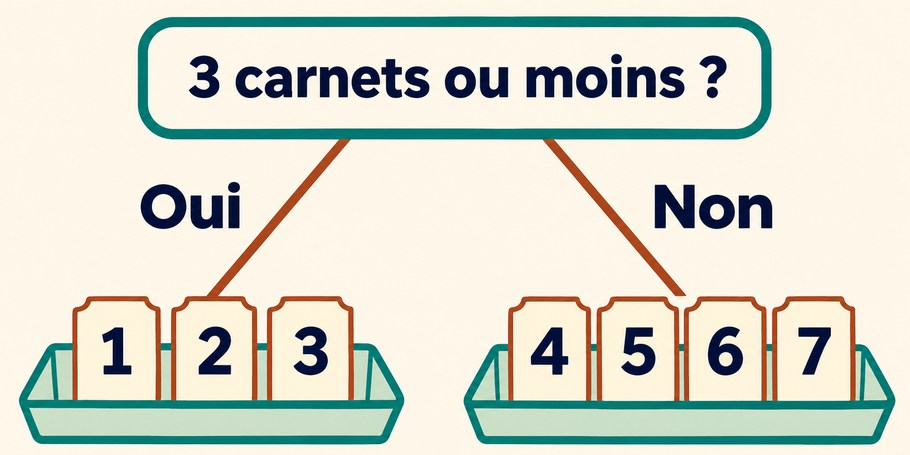

> Suis le ticket de six carnets dans le dessin. Combien de commandes de son bac ont fini en retard ? Quelle classe proposerais-tu pour une nouvelle commande de six carnets ?

<details><summary>Suivre le ticket</summary>

Six carnets conduisent au bac de droite. Trois des quatre commandes de ce bac ont fini en retard. L’imprimeur proposerait donc « en retard ». Le bon de cinq carnets était pourtant à l’heure.

</details>

Un modèle peut apprendre à trier les bons comme sur le dessin. Il essaie plusieurs coupures et cherche celle qui sépare le mieux les commandes à l’heure de celles en retard, en tenant compte de la taille des groupes. Ce modèle s’appelle un **arbre de décision**. Le bac où s’arrête le trajet d’un bon est une **feuille** de l’arbre.

Dans chaque feuille, l’arbre compte la part des commandes en retard. Pour une nouvelle commande dans cette feuille, le nombre obtenu s’appelle le **score** de retard. Dans le bac de droite, il vaut 3/4, soit 0,75. Quatre et sept carnets obtiennent ainsi le même score. Comment faire varier l’estimation d’un carnet au suivant ?

### Faire varier le score avec la quantité

Imagine que l’imprimeur commence par attribuer le même score à toutes ses commandes. Il reprend les anciens bons. S’il avait donné un score proche de zéro à un bon livré en retard, il aurait beaucoup sous-estimé la possibilité d’un retard. Ces écarts vont servir à ajuster le calcul.

Le modèle apprend deux nombres. Le premier fixe un point de départ. Le second règle l’effet d’un carnet supplémentaire et s’appelle le **poids** du nombre de carnets. Le modèle multiplie la quantité par ce poids, ajoute le point de départ et ramène le résultat entre 0 et 1 au moyen d’une courbe en S. Si le poids est positif, le score monte à chaque carnet ajouté. C’est ainsi que fonctionne ici la **régression logistique**. Pendant `fit`, elle ajuste les deux nombres en comparant ses scores aux retards enregistrés.

Si le modèle donne 0,75 à une série de commandes, il y prévoit environ trois retards sur quatre. C’est dans ce sens que l’on parle de **probabilité estimée**. Il faudrait observer de nombreuses livraisons pour vérifier si cette estimation tient.

Aux archives, une équipe reçoit aussi des scores, mais elle ne peut relire que deux fiches. Comment passer d’un nombre inscrit sur chaque fiche à une liste de fiches à relire ?

## Visualiser · Quatre fiches et deux places

L’équipe cherche une mention particulière dans ses archives. Sur ces quatre fiches fictives, 1 signifie que la mention figure sur l’original, 0 qu’elle en est absente. Chaque fiche a aussi reçu un score. L’équipe masque les étiquettes d’origine le temps de faire son choix.

| Fiche | A | B | C | D |
|---|---:|---:|---:|---:|
| Score pour la classe 1 | 0,12 | 0,37 | 0,58 | 0,84 |
| Étiquette enregistrée | 0 | 1 | 0 | 1 |

L’équipe fixe une limite. Quand le score atteint ou dépasse cette limite, la fiche va dans la pile à relire et reçoit la classe proposée 1. En dessous, on l’écarte et on propose 0. La limite choisie s’appelle le **seuil de décision**.

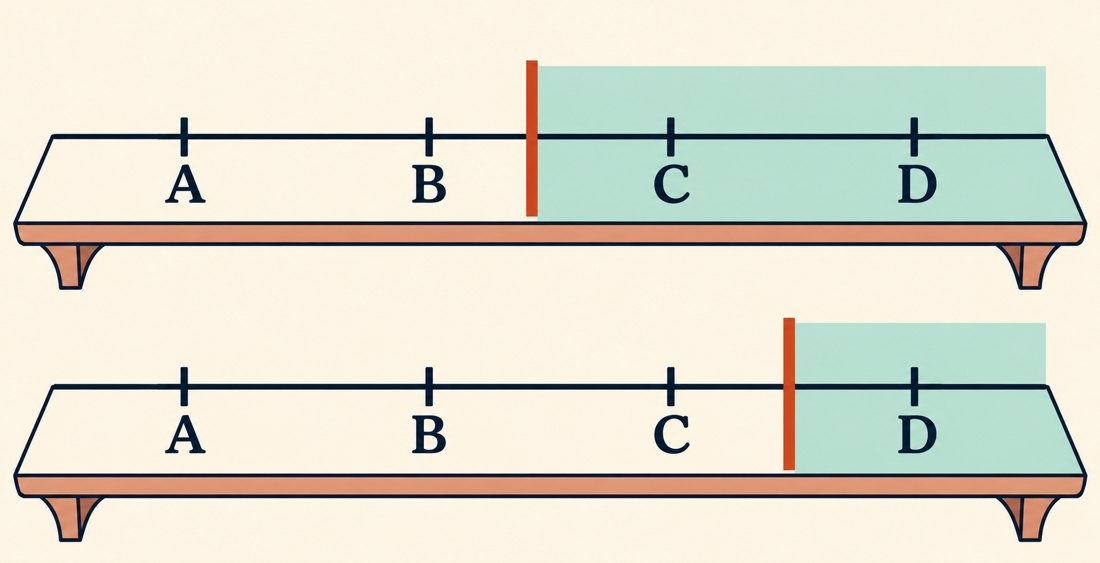

> Cache la dernière ligne du tableau. Quelles lettres vas-tu relire au seuil de 0,50 ? Au seuil de 0,70 ? Découvre ensuite la ligne. Quelle mention manque dans les deux listes ?

<details><summary>Vérifier les deux listes</summary>

Au seuil de 0,50, on relit C et D. Seule D porte effectivement un 1. Au seuil de 0,70, on relit seulement D. C libère une place, mais B, qui porte aussi un 1, manque dans les deux listes. Aucun score n’a changé entre les deux décisions.

</details>

Pour juger le tri, il faut aussi regarder la pile écartée. Comment compter à la fois les mentions oubliées et les relectures inutiles ?

## Approfondir · Quelles fiches ont été bien classées ?

Reprends le seuil de **0,70**. Sur papier, fais une colonne pour les fiches écartées et une autre pour les fiches retenues. Place les quatre lettres dans ces colonnes. Consulte ensuite les étiquettes et entoure les lettres des fiches qui portent la mention.

<details><summary>Vérifier où se trouvent les quatre fiches</summary>

| Étiquette enregistrée ↓ / Décision de l’équipe → | 0 · écartée | 1 · retenue |
|---|---:|---:|
| 0 · mention absente | A et C (2) | aucune (0) |
| 1 · mention présente | B (1) | D (1) |

</details>

D a été retenue à juste titre. C’est un **vrai positif**. Une fiche retenue par erreur serait un **faux positif**. Il n’y en a aucune ici.

Dans l’autre pile, A et C ont été écartées à juste titre. Ce sont les **vrais négatifs**. B porte la mention et a été écartée par erreur. C’est le **faux négatif**.

Le tableau qui réunit ces quatre comptes s’appelle la **matrice de confusion**. Les lignes suivent les étiquettes d’origine et les colonnes les décisions de l’équipe. Comment résumer ce tri si l’on veut rendre compte du travail de relecture autant que des mentions oubliées ?

### Quatre questions à poser aux comptes

**Sur les quatre fiches, combien ont suivi le bon chemin ?** A et C ont été écartées à juste titre et D a été retenue à juste titre. Cela fait trois décisions correctes sur quatre, soit 75 %. Cette proportion s’appelle l’**exactitude** (*accuracy*).

**Sur les fiches que l’équipe a pris le temps de relire, combien portaient la mention ?** D était la seule fiche relue. Elle portait bien la mention. Le calcul donne 1 sur 1, soit 100 %. La part des fiches qui portent la mention dans la pile des relectures s’appelle la **précision** (*precision*).

Pars maintenant des fiches qui portaient la mention, B et D. **Combien l’équipe en a-t-elle retrouvées ?** Seulement D. Cette fois, la même trouvaille se rapporte à deux mentions. Cela donne 1 sur 2, soit 50 %. La part des mentions retrouvées s’appelle le **rappel** (*recall*).

L’équipe voudrait parfois un seul nombre qui tienne compte de ces deux proportions. Écris tes deux listes côte à côte. Celle des relectures contient D, celle des mentions à retrouver contient B et D. Tu as écrit trois lettres. D, la seule mention retrouvée, figure une fois dans chaque liste. Ses deux apparitions sur trois donnent 2/3, soit environ 67 %. Ce calcul s’appelle le **score F1**. Une mention retrouvée compte deux fois, une fausse alerte ou une mention manquée une seule fois, et les fiches correctement écartées ne figurent dans aucune des deux listes.

<details><summary>Retrouver les quatre formules</summary>

Ces quatre mesures sont aussi appelées des *métriques*. Le F1 est la moyenne dite *harmonique* de la précision et du rappel. Elle est plus proche de la plus petite des deux valeurs. Dans ces formules, VP et VN désignent les vrais positifs et négatifs, FP et FN les faux positifs et négatifs.

| Mesure | Calcul |
|---|---|
| Exactitude | (VN + VP) / nombre total de fiches |
| Précision | VP / (VP + FP) |
| Rappel | VP / (VP + FN) |
| F1 | 2 × VP / (2 × VP + FP + FN) |

</details>

Une règle retient zéro fiche. Pour laquelle de ces mesures diviserait-on par zéro quand le lot contient des mentions à retrouver ?

<details><summary>Vérifier le calcul</summary>

La précision est indéfinie puisqu’aucune fiche n’est retenue. Le rappel vaut zéro dès qu’il y avait des fiches portant la mention à retrouver. Un logiciel peut afficher 0 pour la précision par convention.

</details>

Sur les quatre fiches, les scores étaient déjà inscrits. Comment obtenir de tels scores quand on ne dispose au départ que des renseignements et des étiquettes des anciens dossiers ?

## Coder · Apprendre à classer avec l’âge seul

Nous allons apprendre à attribuer un score d’après l’âge. Le fichier AVC contient **5 110 dossiers**. La rubrique `stroke` vaut **1 si un accident vasculaire cérébral est renseigné**, et **0 sinon**. Pour l’exercice, l’équipe masque cette rubrique sur les fiches à classer. Elle la découvrira ensuite pour vérifier les résultats. La date des mesures par rapport à l’événement est inconnue. Les résultats concernent la recherche d’une mention dans les archives. Ils ne permettent ni diagnostic ni estimation d’un risque futur pour une personne.

L’arbre et la régression logistique recevront exactement les mêmes âges. On pourra ainsi comparer leurs façons d’apprendre. Exécute la cellule repliée pour charger le tableau inclus dans le cahier.

Parmi ces 5 110 fiches, lesquelles garder de côté pour choisir un seuil, puis vérifier ce choix ?

In [1]:
from pathlib import Path
import pandas as pd

def tableau_du_cahier():
    dossier = Path(globals().get("__vsc_ipynb_file__") or ".").parent
    for chemin in [dossier.resolve().parent / "data/donnees_stroke.csv", Path("data/donnees_stroke.csv")]:
        if chemin.is_file():
            return pd.read_csv(chemin)
    raise FileNotFoundError("donnees_stroke.csv introuvable : place-le dans le dossier data du projet, puis relance cette cellule.")

donnees = tableau_du_cahier()
print(len(donnees), "lignes chargées.")


5110 lignes chargées.


### Réserver des fiches pour chaque étape

Chaque exemple d’apprentissage associe un âge et une réponse connue. Le code les sépare. `X` contient le renseignement qu’on leur fournit, ici l’âge. `y` contient la réponse connue, l’étiquette 0 ou 1. Les premiers dossiers du fichier portent tous un 1. On mélange donc les lignes avant de les répartir.

Imagine trois piles. Dans la première, les modèles pourront lire les âges et les étiquettes pour apprendre. Cette pile d’**apprentissage** reçoit 60 % des fiches. La deuxième servira à essayer plusieurs seuils et à choisir celui qu’on garde. C’est la **validation**, 20 % des fiches. La troisième, le **test**, reste de côté jusqu’à ce que toute la règle soit fixée.

Dans le code, `train_test_split` effectue les partages en deux fois. Il met d’abord de côté les 20 % du test. Sur les 80 % restants, il en réserve un quart pour la validation, soit 20 % du total.

In [9]:
from sklearn.model_selection import train_test_split

X = donnees[["age"]]
y = donnees["stroke"]

def train_test_val_split(X, y):
    X_dev, X_test, y_dev, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=42
    )
    X_ap, X_val, y_ap, y_val = train_test_split(
        X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=42
    )
    return X_test, y_test, X_ap, X_val, y_ap, y_val

X_test, y_test, X_ap, X_val, y_ap, y_val = train_test_val_split(X, y)

print("Apprentissage :", len(X_ap), "dossiers.")
print("Validation :", len(X_val), "dossiers, dont", y_val.sum(), "codés 1.")

Apprentissage : 3066 dossiers.
Validation : 1022 dossiers, dont 50 codés 1.


Les doubles crochets de `donnees[["age"]]` gardent l’âge sous forme de tableau. Dans le partage, `stratify=y` demande de garder des proportions voisines de 0 et de 1 dans les lots. `random_state=42` permet de retrouver le même tirage à chaque exécution.

La pile de validation contient **1 022 dossiers**. Pour compter les mentions, le code additionne leurs étiquettes avec `y_val.sum()`. Chaque 1 ajoute une unité et chaque 0 n’ajoute rien. Cela donne 50 mentions à retrouver.

Avant d’ajuster les modèles, essayons une règle toute simple qui propose 0 pour tout le monde. Elle nous servira de **référence**. Quel bilan annoncerais-tu à l’équipe chargée de retrouver les 1 ?

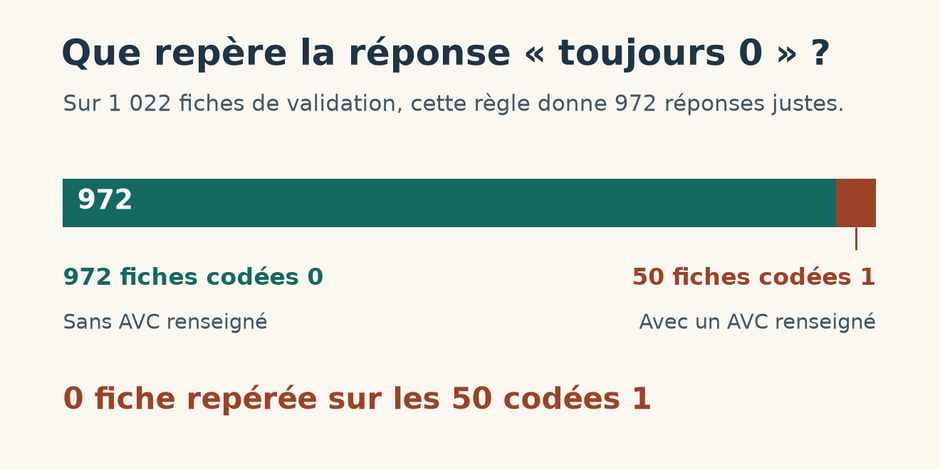

Cette règle atteint environ **95 % d’exactitude** (972/1 022) et **0 % de rappel** (0/50). La plupart des fiches sont déjà des 0. Pour faire mieux que cette règle qui manque les 50 mentions, que peuvent apprendre les deux modèles des âges des 3 066 dossiers d’apprentissage ?

### Comment les deux modèles utilisent l’âge

L’arbre cherche une première question de la forme « L’âge dépasse-t-il telle valeur ? ». Pour que tu puisses suivre chaque décision à la main, on lui permet de poser une seule question par trajet. C’est le réglage `max_depth=1`, une **profondeur** maximale de 1.

La régression logistique cherche de combien l’âge doit faire varier le score. Dans la cellule, `fit` veut dire « ajuste le modèle avec ces exemples ». Les deux appels voient les mêmes âges `X_ap` et les mêmes étiquettes `y_ap`.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text

arbre = DecisionTreeClassifier(max_depth=1, random_state=42)
logistique = LogisticRegression(max_iter=1000)

arbre.fit(X_ap, y_ap)
logistique.fit(X_ap, y_ap)

print(export_text(arbre, feature_names=["âge"], show_weights=True))
print("Ordre des classes :", logistique.classes_)

|--- âge <= 67.50
|   |--- weights: [2482.00, 61.00] class: 0
|--- âge >  67.50
|   |--- weights: [435.00, 88.00] class: 0

Ordre des classes : [0 1]


La première ligne de l’arbre se lit « **âge inférieur ou égal à 67,5 ans ?** ». Ici, les deux nombres après `weights` comptent les fiches dans l’ordre **[classe 0, classe 1]**. Dans la branche « oui », 61 des 2 543 fiches portent un 1. Dans la branche « non », il y en a 88 sur 523. Le 0 reste majoritaire dans les deux feuilles. Pour obtenir leurs scores de la classe 1, divise le nombre de 1 par le nombre de fiches de chaque feuille. On trouve environ **0,024** et **0,168**.

`max_iter=1000` donne à la régression logistique jusqu’à mille essais pour ajuster son calcul. `classes_` indique l’ordre des classes, ici 0 puis 1. Quand on demandera leurs scores avec `predict_proba`, la deuxième colonne sera donc celle des mentions recherchées.

Si l’on passe d’une fiche de 55 ans à une autre de 65 ans, les deux modèles changent-ils de score ?

### Comparer deux modèles aux mêmes âges

> Avant d’exécuter la cellule, note le score que tu attends de l’arbre à 55 et à 65 ans. Fais le même pronostic pour un dossier de 75 ans.

La cellule crée cinq fiches fictives, puis appelle `predict_proba` pour chacune. Dans `[:, 1]`, les deux-points gardent toutes les fiches et `1` désigne la deuxième colonne, car Python numérote les colonnes à partir de zéro. C’est le score pour la mention recherchée. `predict`, qui remplit la dernière colonne, demande à l’arbre de choisir une classe. `round(3)` arrondit seulement le tableau affiché.

In [ ]:
exemples = pd.DataFrame({"age": [45, 55, 65, 70, 75]})
comparaison = exemples.copy()
comparaison["Score arbre"] = arbre.predict_proba(exemples)[:, 1]

print("-----")
print(arbre.predict_proba(exemples))
print("-----")


# comparaison["Score logistique"] = logistique.predict_proba(exemples)[:, 1]
# comparaison["Classe proposée par l’arbre"] = arbre.predict(exemples)
# print(comparaison.round(3).to_string(index=False))

-----
[[0.97601258 0.02398742]
 [0.97601258 0.02398742]
 [0.97601258 0.02398742]
 [0.83173996 0.16826004]
 [0.83173996 0.16826004]]
-----


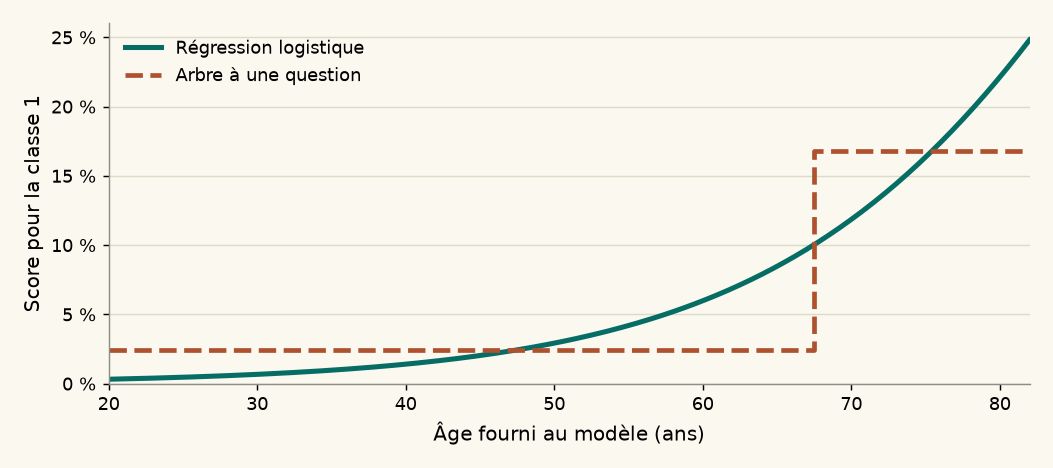

À **55 et 65 ans**, l’arbre reste dans la même feuille et donne deux fois le score 0,024. Pour les deux mêmes fiches, la régression logistique passe de 0,042 à 0,085. Elle a appris un poids positif pour l’âge. À **75 ans**, le score de l’arbre passe à 0,168 dans la seconde feuille, tandis que celui de la logistique atteint environ **0,164** par une progression continue. Le dessin montre leurs scores entre 20 et 82 ans.

Dans le tableau, `predict` propose toujours la classe majoritaire de la feuille, donc 0. Pour organiser une relecture, nous pouvons appliquer **notre propre seuil** aux scores de `predict_proba`. Comment choisir le modèle et son seuil si l’équipe ne peut relire que 153 fiches ?

### Choisir une règle avec 153 places de relecture

L’équipe peut relire **au plus 15 % des 1 022 dossiers de validation**, soit **153 places** après arrondi à l’entier inférieur. Parmi les règles compatibles, elle veut **retrouver le plus de dossiers codés 1**. À résultat égal, elle préfère la liste la plus courte.

Pour chaque modèle, essaie les seuils **0,08, 0,13 et 0,17**, fixés avant la comparaison. Cela fait six règles à examiner. Chaque passage dans la boucle `for seuil in seuils` essaie l’une des trois limites. Le code compte d’abord les fiches qui atteignent ou dépassent cette limite, puis celles qui portent effectivement un 1 parmi les fiches retenues.

In [16]:
seuils = [0.08, 0.13, 0.17]
modeles = {"Logistique": logistique, "Arbre": arbre}
essais = []

for nom, modele in modeles.items():
    scores = modele.predict_proba(X_val)[:, 1]

    for seuil in seuils:
        retenues = scores >= seuil
        essais.append({
            "modèle": nom,
            "seuil": seuil,
            "à relire": int(retenues.sum()),
            "1 retrouvés": int(y_val[retenues].sum()),
        })

resultats = pd.DataFrame(essais)
display(resultats)

,modèle,seuil,à relire,1 retrouvés
0,Logistique,0.08,201,31
1,Logistique,0.13,133,23
2,Logistique,0.17,93,18
3,Arbre,0.08,170,28
4,Arbre,0.13,170,28
5,Arbre,0.17,0,0


`retenues` contient une valeur vraie ou fausse par dossier. La somme compte les valeurs vraies. `y_val[retenues]` garde les étiquettes de ces seuls dossiers. Leur somme compte les vrais positifs.

> Barre les lignes qui dépassent 153 places. Parmi les lignes restantes, entoure celle qui retrouve le plus de 1. Quelle ligne donne zéro relecture ? Retrouve dans les deux feuilles de l’arbre l’explication de ce zéro.

In [6]:
def choisir_regle(tableau, places):
    possibles = tableau[tableau["à relire"] <= places]
    classement = possibles.sort_values(
        ["1 retrouvés", "à relire"], ascending=[False, True]
    )
    return classement.iloc[0]

places = int(0.15 * len(X_val))
choix = choisir_regle(resultats, places)
print(choix.to_string())

modèle         Logistique
seuil                0.13
à relire              133
1 retrouvés            23


Le tri classe d’abord les vrais positifs du plus grand au plus petit, puis la longueur des listes de la plus petite à la plus grande. `iloc[0]` garde la première ligne du tableau ainsi trié. **La logistique au seuil de 0,13** demande **133 relectures** et retrouve **23 dossiers codés 1**. Pour l’arbre, 0,17 dépasse même le score de sa feuille la plus riche en 1. Il ne propose alors aucune fiche.

Avec la logistique à 0,13, on aurait donc 23 mentions dans la pile à relire. Que représentent ces 23 mentions pour l’équipe qui relit 133 fiches et qui cherche 50 mentions ?

### Faire le bilan de la règle choisie

Dans la matrice, la colonne « Proposé 1 » détaille les 133 fiches retenues. La ligne « Enregistré 1 » détaille les 50 mentions recherchées. La cellule recalcule ces deux comptes sur la validation. `scores_choisis >= choix["seuil"]` vérifie le passage du seuil et `astype(int)` écrit 1 pour « oui », 0 pour « non ».

Aux fonctions de scikit-learn qui calculent les quatre mesures, on donne d’abord les étiquettes enregistrées, puis les propositions. On donne le même ordre à `confusion_matrix` et on précise `labels=[0, 1]` pour retrouver la disposition du tableau des quatre fiches.

In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

scores_choisis = modeles[choix["modèle"]].predict_proba(X_val)[:, 1]
propositions = (scores_choisis >= choix["seuil"]).astype(int)
matrice = confusion_matrix(y_val, propositions, labels=[0, 1])
print(pd.DataFrame(matrice, index=["Enregistré 0", "Enregistré 1"],
                   columns=["Proposé 0", "Proposé 1"]).to_string())
print()
for nom, mesure in [("Exactitude", accuracy_score), ("Précision", precision_score),
                    ("Rappel", recall_score), ("F1", f1_score)]:
    print(f"{nom} : {mesure(y_val, propositions):.1%}")

              Proposé 0  Proposé 1
Enregistré 0        862        110
Enregistré 1         27         23

Exactitude : 86.6%
Précision : 17.3%
Rappel : 46.0%
F1 : 25.1%


L’équipe relirait **110 dossiers sans la mention** et **23 avec la mention**. Il reste **27 dossiers codés 1** parmi les fiches écartées. La précision vaut 23/133, soit environ **17,3 %**. Le rappel vaut 23/50, soit **46 %**. Ces deux pourcentages utilisent les mêmes 23 dossiers et répondent à deux questions différentes.

Ces résultats viennent du lot qui a servi à choisir la règle. Le **test** servira à estimer la performance de la règle fixée sur d’autres dossiers. Il reste fermé pendant tous les essais de ce chapitre.

Sur la validation, 27 mentions ont échappé à la relecture. En ouvrant une permanence de plus, combien pourrait-on en récupérer et pour quel travail supplémentaire ?

## Pratiquer · Que rapporte une permanence supplémentaire ?

**1. Sur papier.** Avant de chiffrer la permanence, observe sur les quatre fiches A, B, C et D ce que changerait une liste de relecture plus longue. Cette fois, le seuil vaut **0,30**. Note les fiches retenues, remplis les quatre cases de la matrice et calcule l’exactitude, la précision, le rappel et le F1. Quelles fiches changent de colonne par rapport au seuil de 0,70 ?

**2. Sur les dossiers de validation.** Avec la permanence supplémentaire, l’équipe pourrait relire **20 % des dossiers**. Utilise les six règles déjà essayées. Calcule le nombre entier de places, repère la règle qui retrouve le plus de 1 dans cette limite et compare-la avec le choix à 15 %. Combien de fiches supplémentaires faut-il relire ? Combien de dossiers codés 1 supplémentaires retrouve-t-on ?

Essaie d’abord en lisant `resultats`. Tu peux ensuite compléter la cellule ci-dessous pour contrôler tes calculs.

In [8]:
# Exécute ce rappel, puis ajoute tes propres calculs à la suite.
print(resultats.to_string(index=False))
# places_sup = ...
# autre_choix = choisir_regle(resultats, places_sup)

    modèle  seuil  à relire  1 retrouvés
Logistique   0.08       201           31
Logistique   0.13       133           23
Logistique   0.17        93           18
     Arbre   0.08       170           28
     Arbre   0.13       170           28
     Arbre   0.17         0            0


<details><summary>Indice</summary>

À 0,30, compare le score de chaque fiche à la nouvelle limite. Pars de la liste des lettres retenues, puis cherche les étiquettes correspondantes. Pour la permanence, `len(X_val)` compte les fiches de validation. Multiplie ce nombre par 0,20. `int` te donne le nombre de places entières. Garde les mêmes critères de départage.

</details>

<details><summary>Corrigé des quatre fiches</summary>

À 0,30, on retient **B, C et D**. **B** apporte le second vrai positif et **C** une fausse alerte supplémentaire par rapport à 0,70. A est le seul vrai négatif.

| Étiquette enregistrée ↓ / Classe proposée → | 0 | 1 |
|---|---:|---:|
| 0 | 1 (A) | 1 (C) |
| 1 | 0 | 2 (B, D) |

**Exactitude** 3/4 = 75 %. **Précision** 2/3 ≈ 67 %. **Rappel** 2/2 = 100 %. **F1** 4/(4 + 1 + 0) = 80 %. L’exactitude est la même qu’à 0,70. Le type d’erreur et le nombre de relectures ont changé.

</details>

<details><summary>Corrigé de la permanence</summary>

La limite devient **204 places**. La **logistique au seuil de 0,08** retient **201 fiches**, dont **31 dossiers codés 1**. Par rapport aux 133 fiches et aux 23 dossiers codés 1, l’équipe ferait **68 relectures de plus** et retrouverait **8 dossiers codés 1 supplémentaires** sur ce lot. L’équipe peut discuter de ce gain sans réentraîner le modèle.

```python
places_sup = int(0.20 * len(X_val))
autre_choix = choisir_regle(resultats, places_sup)
print(autre_choix)
print(autre_choix["à relire"] - choix["à relire"])
print(autre_choix["1 retrouvés"] - choix["1 retrouvés"])
```

</details>

L’équipe doit maintenant décider si elle ouvre cette permanence. Quels chiffres lui présenterais-tu pour qu’elle puisse juger du travail demandé et du gain attendu ?

## Retenir · Expliquer une décision de classement

Dans ton compte rendu, donne ensemble le nombre de relectures supplémentaires et le nombre de mentions retrouvées en plus. Précise que tu les as comptées sur les fiches de validation.

- **Du modèle à l’action.** L’arbre apprend des questions et attribue un score par feuille. La régression logistique apprend des poids et produit un score qui varie progressivement. Le seuil traduit ce score en proposition de classe.
- **Deux erreurs différentes.** Un faux positif occupe une place de relecture. Un faux négatif laisse de côté une fiche recherchée. Lis les lignes et les colonnes de la matrice avant de commenter un chiffre.
- **Un résultat se rapporte à une question.** L’exactitude compte toutes les décisions justes. La précision renseigne sur les fiches retenues, le rappel sur celles qu’on voulait retrouver. Le F1 combine précision et rappel.
- **Un choix se vérifie sur des données tenues à part.** Compare les règles sur la validation en fonction des places disponibles. Une fois la règle fixée, le test permettra d’en estimer les résultats sur un autre lot.

Chacun de nos modèles donne le même score à deux dossiers du même âge. Les fiches contiennent pourtant d’autres renseignements. Comment les utiliser quand certains sont écrits en toutes lettres ou que des cases sont vides ?